# Homework 2. Deep learning

In this homework you will play with deep neural networks in PyTorch: write pieces of code for training/testing routine, train a simple baseline network, design your own architecture and pick parameters to beat the baseline, fine-tune two pre-trained deep neural nets (a ResNet and a Vision Transformer), create a simple region proposal net and compare it with a modern object detector, and finally generate images with pre-trained text-to-image diffusion models.

The homework is graded out of 50 points:
1. (5 points) implement testing loop and measure accuracy;
2. (10 points) design your architecture and beat the baseline accuracy on the CIFAR-10 dataset (better accuracy -> more points);
3. (5 points) fine-tune ResNet-50 on the Dogs-vs-Cats dataset;
4. (5 points) fine-tune ViT-Small on the Dogs-vs-Cats dataset and compare it with ResNet-50;
5. (5 points) use your model to create a simple region proposal net;
6. (5 points) run a YOLO detector and compare it with your region proposals;
7. (10 points) text-to-image generation: study the effect of the noise, the number of sampling steps, and the choice of model;
8. (15 points) discussion: answer seven short **Discussion** prompts inside this notebook (a few sentences each, about your experimental results).

This is a coding assignment: there is no separate report. Write your answers to the Discussion prompts directly in the corresponding markdown cells.

### Submission format:

Notebook with your work (shared link or `.ipynb`), **with all outputs saved**.

You can save a copy of this notebook in Colab and just submit the link, or download the `.ipynb` notebook and submit that way. Please make sure that your link is properly shared (it's best to pick "**everyone with the link can comment**"), or make sure that your `.ipynb` has all your outputs (there is an option to download just the code/text-only lightweight version). The generated images in Section 5 must be visible in the saved outputs.

Before you submit, make sure your notebook runs from start to end through **"Runtime -> Restart and Run all"**. If it doesn't, this likely means you executed cells out-of-order, or created variables with inconsistent names (e.g. one of the cells was using an output of a temporary variable from a cell that you deleted). Your results can also differ if you execute the training loop several times without resetting the network (making more epochs, which may result in a better result, but may also lead to overfitting).

# Notes on using Google Colab

**Important: make sure your work is saved to your Google Drive or Github before starting**

`File --> Save a copy...`. See the [docs](https://www.tutorialspoint.com/google_colab/google_colab_saving_work.htm).

In the top right corner you can see the available resources (RAM, Disk, etc.). Click on that button to expand the tab. By default you may get a CPU-only machine allocated. You can request an instance with a GPU through `Runtime -> Change runtime type` in the file menu bar. Public GPUs may not always be available. CPU is sufficient for Sections 1-4, as you don't need to train the models from scratch on large datasets (fine-tuning in Section 3 is much faster on a GPU though). **Section 5 (diffusion models) requires a GPU runtime.** Free GPUs are not always available and sessions have a time limit, so plan ahead: run Sections 1-4 first, save the notebook, and run Section 5 in a separate session if needed.

In [1]:
%pip install -q timm==1.0.22 ultralytics==8.3.228 diffusers==0.35.2 transformers==4.57.3 accelerate==1.12.0 matplotlib pandas


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\derpi\Documents\Codex\2026-10-14\referenced-chatgpt-conversation-this-is-an\work\venv\Scripts\python.exe -m pip install --upgrade pip


In [2]:
%matplotlib inline
import os, time, zipfile, random, json, gc, copy, urllib.request
from pathlib import Path
import importlib.metadata
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageDraw
from IPython.display import display
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import random_split, DataLoader
import torchvision
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder
from torchvision.models import resnet50, ResNet50_Weights

SEED = 42
def seed_all(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
seed_all()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(min(2, os.cpu_count() or 1))
if os.name == 'nt':
    import psutil
    task_process = psutil.Process()
    task_process.nice(psutil.BELOW_NORMAL_PRIORITY_CLASS)
    task_process.cpu_affinity(task_process.cpu_affinity()[-2:])
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
DATA_ROOT = Path('homework_data')
DATA_ROOT.mkdir(exist_ok=True)
os.environ['HF_HOME'] = str((DATA_ROOT / 'hf_cache').resolve())
os.environ['TORCH_HOME'] = str((DATA_ROOT / 'torch_cache').resolve())
ARTIFACT_ROOT = DATA_ROOT / 'experiment_artifacts'
ARTIFACT_ROOT.mkdir(exist_ok=True)
(ARTIFACT_ROOT / 'training_progress.jsonl').write_text('')
metrics = {}
def save_metrics():
    (ARTIFACT_ROOT / 'metrics.json').write_text(json.dumps(metrics, indent=2))
print('Device:', device)
if device.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
    print('VRAM (GiB):', round(torch.cuda.get_device_properties(0).total_memory / 2**30, 2))
print({p: importlib.metadata.version(p) for p in ['torch','torchvision','timm','ultralytics','diffusers','transformers','accelerate']})


Device: cuda
GPU: NVIDIA GeForce RTX 3060 Ti
VRAM (GiB): 8.0
{'torch': '2.11.0+cu128', 'torchvision': '0.26.0+cu128', 'timm': '1.0.22', 'ultralytics': '8.3.228', 'diffusers': '0.35.2', 'transformers': '4.57.3', 'accelerate': '1.12.0'}


In [3]:
def to_device(obj):
    return obj.to(device)

def synchronize():
    if torch.cuda.is_available():
        torch.cuda.synchronize()

# Zero workers avoids Windows notebook multiprocessing issues.
def make_loader(dataset, batch_size=32, shuffle=False, seed=SEED):
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle,
                      num_workers=0, pin_memory=torch.cuda.is_available(),
                      generator=torch.Generator().manual_seed(seed))


# 1. CIFAR-10 image classification

## 1.1 CIFAR-10 data


The [CIFAR-10 dataset](https://www.cs.toronto.edu/~kriz/cifar.html) is a well-known image classification dataset that contains 60,000 32x32 color images in 10 classes, with 6,000 images per class. The goal of image classification is to correctly classify each image into its corresponding class label.

Achieving high accuracy on CIFAR-10 can be challenging, as the images are relatively small and contain many details, making it difficult to distinguish between some of the classes.

We will create a simple convolutional neural network and train it to achieve good baseline accuracy.

But first, let's look at some of the CIFAR-10 data samples. It's always beneficial to understand your data before attempting to solve the problem!

Luckily, PyTorch's `torchvision` package has a native CIFAR-10 dataset implementation, so creating the dataset can be as simple as `data = torchvision.datasets.CIFAR10(root='./data', download=True)`. However, we will need a couple more things to make it handy for network training.

First, define a preprocessing function that is used to transform the images in the dataset. In this case, the `ToTensor` transform is used to convert the images to PyTorch tensors, and the `Normalize` transform is used to normalize the tensor values to some range to facilitate the network convergence.

Second, remember to use different datasets for training and testing. `CIFAR10` handles that through the `train` flag already, but normally you would split the dataset into two parts to test on unseen images.


Finally, create data loaders that iterate over the train and test sets. The `batch_size` and `shuffle` arguments specify the iteration batch size and whether the data should be shuffled between epochs, and the `num_workers` argument specifies the number of subprocesses to use for data loading.

In [4]:
preprocess = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,)*3, (0.5,)*3)
])
# Unmodified university mirror; torchvision checks the original archive MD5.
torchvision.datasets.CIFAR10.url = ('https://huggingface.co/datasets/MIT-OL-AI-D/cifar-10-python/'
    'resolve/a48007227f9e2cd0af96175f4afb5ac4965e261b/cifar-10-python.tar.gz')
cifar_train = torchvision.datasets.CIFAR10(root=str(DATA_ROOT), train=True,
                                         download=True, transform=preprocess)
cifar_test = torchvision.datasets.CIFAR10(root=str(DATA_ROOT), train=False,
                                        download=True, transform=preprocess)
batch_size = 32
cifar_train_loader = make_loader(cifar_train, batch_size, True)
cifar_test_loader = make_loader(cifar_test, batch_size)
print('CIFAR-10:', len(cifar_train), 'train;', len(cifar_test), 'test')


CIFAR-10: 50000 train; 10000 test


In order to show the images in the batch, we now need to un-normalize them since the original images were normalized during the dataset loading process. Let's plot the first few images from the batch and print their labels.

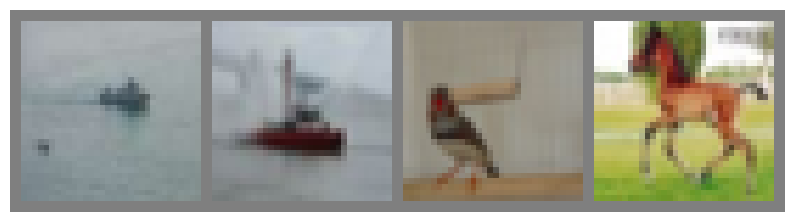

ship ship bird horse


In [5]:
def show_images(img, mean, std):
    img = img.detach().cpu().permute(1, 2, 0)
    img = img * torch.tensor(std) + torch.tensor(mean)
    plt.figure(figsize=(10, 3))
    plt.imshow(img.clamp(0, 1).numpy())
    plt.axis('off')
    plt.show()
images, labels = next(iter(cifar_train_loader))
nimages = min(batch_size, 4)
norm = preprocess.transforms[-1]
show_images(torchvision.utils.make_grid(images[:nimages]), norm.mean, norm.std)
print(' '.join(cifar_train.classes[int(labels[j])] for j in range(nimages)))


## 1.2 Baseline network

The SimpleNet class below inherits from the nn.Module class, which is a base class for all neural network modules in PyTorch. The __init__ method initializes the various layers of the neural network, while the forward method defines the forward pass through the network. Notice that you don't have to implement the backward pass when using superpositions of standard functions and layers, since the corresponding backward pass is already implemented for these standard operations, and the backward pass for your full model is simply derived from those using the chain rule.

Our network consists of two convolutional layers (conv1 and conv2) followed by two fully connected layers (fc1 and fc2), and a final output layer (fc3) with 10 output units (one for each class in the CIFAR-10 dataset). It also has a 2x down-sampling `pool` layer (applied after both conv1 and conv2), and ReLU nonlinearities between the layers.

The input to the network is a batch of 32x32 color images (3 channels for RGB) and the output is a tensor of shape (batch_size, 10) representing the predicted class scores for each input image in the batch.

In [6]:
class SimpleNet(nn.Module):
    def __init__(self, input_size=32, num_classes=10):
        # define the layers of the network
        super(SimpleNet, self).__init__()
        # 3 input channels: RGB
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=6, kernel_size=5)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(in_channels=6, out_channels=16, kernel_size=5)
        self.fc1 = nn.Linear(in_features=16 * 5 * 5, out_features=120)
        self.fc2 = nn.Linear(in_features=120, out_features=84)
        # num_classes output channels
        self.fc3 = nn.Linear(in_features=84, out_features=num_classes)

    def forward(self, x):
        # Remember to use nonlinearities after hidden linear layers (conv, fc)
        # Convolutional layers
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        # Reshape as a vector
        x = x.view(-1, self.fc1.in_features)
        # Fully connected (fc) layers
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        # Note that the output layer does not need a nonlinearity.
        # as it models log-probability
        x = self.fc3(x)
        return x


model_simple = SimpleNet()
model_simple = to_device(model_simple)

## 1.3 Training and testing the network

In order to train the network, we are still missing a couple things:
1. A loss criterion: for most classification problems, cross-entropy is used to define loss. Luckily, we know ground truth labels for our training dataset, and our network already models log-probability output with its final fully connected layer.

2. An optimizer: we will use SGD with momentum as our base optimizer. You will have to tune its parameters later, and feel free to explore other optimizers available in the `optim` package!

The training code runs over the dataset `nepoch` number of times (epochs).

## TODO #1 (5 points): implement the testing loop

While training code is provided below, you have to implement the testing routine. It's very similar to training, even simpler, as there is no need to make a call into the optimization step! You also have to loop through the data and get network outputs. Instead of computing the loss, let's measure the accuracy of the predictions:
$$\text{accuracy} = \dfrac{\text{number_of_correct_predictions}}{\text{total_samples}} * 100 \%$$

Use `torch.max()` to get the most likely label for every image from its per-class scores.

In [7]:
def test(model, loader):
    model.eval()
    model_device = next(model.parameters()).device
    correct = total = 0
    with torch.no_grad():
        for inputs, labels in loader:
            inputs = inputs.to(model_device, non_blocking=True)
            labels = labels.to(model_device, non_blocking=True)
            with torch.autocast(device_type=model_device.type,
                                enabled=model_device.type == 'cuda'):
                outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            correct += (predicted == labels).sum().item()
            total += labels.numel()
    if total == 0:
        raise ValueError('Cannot evaluate an empty dataset')
    return 100.0 * correct / total

def train_and_test(model, nepochs, train_loader, test_loader,
                   optimizer=optim.SGD, optimizer_params=None,
                   cosine_epochs=None, frozen_backbone=False, label_smoothing=0.0):
    criterion = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
    model_device = next(model.parameters()).device
    params = [p for p in model.parameters() if p.requires_grad]
    opt = optimizer(params, **(optimizer_params or {}))
    scheduler = (optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cosine_epochs)
                 if cosine_epochs else None)
    scaler = torch.amp.GradScaler('cuda', enabled=model_device.type == 'cuda')
    history = []
    best_accuracy = -1
    best_state = None
    for epoch in range(nepochs):
        # Keep frozen BatchNorm statistics and dropout fixed for head-only tuning.
        model.train()
        if frozen_backbone:
            model.eval()
            head = model.fc if hasattr(model, 'fc') else model.head
            head.train()
        synchronize()
        t0 = time.perf_counter()
        loss_sum = samples = 0
        for inputs, labels in train_loader:
            inputs = inputs.to(model_device, non_blocking=True)
            labels = labels.to(model_device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=model_device.type,
                                enabled=model_device.type == 'cuda'):
                outputs = model(inputs)
                loss = criterion(outputs, labels)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            loss_sum += float(loss.detach()) * labels.size(0)
            samples += labels.size(0)
        synchronize()
        train_time = time.perf_counter() - t0
        accuracy = test(model, test_loader)
        history.append(dict(epoch=epoch+1, accuracy=accuracy,
                            train_time=train_time, loss=loss_sum/samples,
                            learning_rate=opt.param_groups[0]['lr']))
        with (ARTIFACT_ROOT / 'training_progress.jsonl').open('a') as progress_file:
            progress_file.write(json.dumps({'model':type(model).__name__, **history[-1]}) + '\n')
        print(f'Epoch {epoch+1}/{nepochs}: loss={loss_sum/samples:.4f}, '
              f'eval accuracy={accuracy:.2f}%, training time={train_time:.2f}s', flush=True)
        if accuracy > best_accuracy:
            best_accuracy = accuracy
            best_state = {k: v.detach().cpu().clone() for k,v in model.state_dict().items()}
        if scheduler:
            scheduler.step()
    if best_state is not None:
        model.load_state_dict(best_state)
    print(f'Restored best evaluation checkpoint: {best_accuracy:.2f}%')
    return history


In [8]:
optimizer_params_default = {'lr': 2e-3, 'momentum': 0.9}
baseline_history = train_and_test(model_simple, 2, cifar_train_loader,
                                  cifar_test_loader, optimizer_params=optimizer_params_default)
metrics['baseline_history'] = baseline_history
save_metrics()


Epoch 1/2: loss=2.0033, eval accuracy=39.43%, training time=21.39s
Epoch 2/2: loss=1.5381, eval accuracy=47.42%, training time=15.36s
Restored best evaluation checkpoint: 47.42%


Now let's look at some predictions


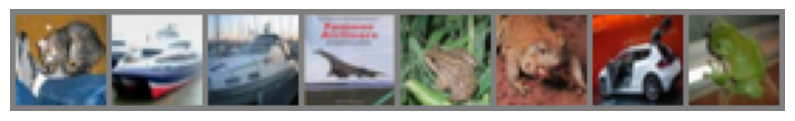

Ground truth: cat ship ship airplane frog frog automobile frog
Predictions:  cat ship ship airplane frog frog dog frog


In [9]:
images, labels = next(iter(cifar_test_loader))
nimages = min(batch_size, 8)
norm = cifar_test.transform.transforms[-1]
show_images(torchvision.utils.make_grid(images[:nimages]), norm.mean, norm.std)
print('Ground truth:', ' '.join(cifar_test.classes[int(y)] for y in labels[:nimages]))
model_simple.eval()
with torch.no_grad():
    _, predictions = torch.max(model_simple(to_device(images[:nimages])), 1)
print('Predictions: ', ' '.join(cifar_test.classes[int(y)] for y in predictions.cpu()))


# 2. Design your own architecture

You can start exploring the space of architectures by tuning the hyperparameters of our baseline network first. Hyperparameters are variables that are not learned from the data, but rather set before the training process begins. They affect how the model is trained and can significantly impact its performance. Those are, for example, learning rate, number of layers (depth), number of neurons per layer (width).

Choosing appropriate hyperparameters is crucial for achieving good performance, and is often done through a combination of trial and error and intuition based on prior experience.


Let's reserve a small validation set for parameter tuning out of our testing data, and test our final model on the test set, minus the validation set.


In [10]:
generator = torch.Generator().manual_seed(42)
cifar_val, cifar_test_minus_val = random_split(cifar_test, [2000, 8000], generator=generator)
cifar_val_loader = make_loader(cifar_val, 128)
cifar_test_minus_val_loader = make_loader(cifar_test_minus_val, 128)
print('Validation:', len(cifar_val), 'Final test:', len(cifar_test_minus_val))


Validation: 2000 Final test: 8000



Try tuning your parameters, and then modify the architecture, adding layers, normalization techniques, etc. from Pytorch's `nn` package.

## TODO #2 (10 points): Implement a stronger network and achieve high accuracy on CIFAR-10

Epoch 1/6: loss=1.8660, eval accuracy=42.10%, training time=17.73s
Epoch 2/6: loss=1.6715, eval accuracy=49.40%, training time=17.37s
Epoch 3/6: loss=1.5919, eval accuracy=51.95%, training time=17.29s
Epoch 4/6: loss=1.5263, eval accuracy=52.60%, training time=18.00s
Epoch 5/6: loss=1.4807, eval accuracy=55.70%, training time=17.47s
Epoch 6/6: loss=1.4483, eval accuracy=57.90%, training time=17.54s
Restored best evaluation checkpoint: 57.90%
Epoch 1/60: loss=1.4495, eval accuracy=60.95%, training time=23.70s
Epoch 2/60: loss=1.0748, eval accuracy=67.70%, training time=24.14s
Epoch 3/60: loss=0.9239, eval accuracy=65.00%, training time=24.09s
Epoch 4/60: loss=0.8374, eval accuracy=78.30%, training time=23.69s
Epoch 5/60: loss=0.7744, eval accuracy=77.70%, training time=23.19s
Epoch 6/60: loss=0.7271, eval accuracy=81.40%, training time=23.89s
Epoch 7/60: loss=0.6917, eval accuracy=80.95%, training time=23.47s
Epoch 8/60: loss=0.6605, eval accuracy=83.15%, training time=23.20s
Epoch 9/60

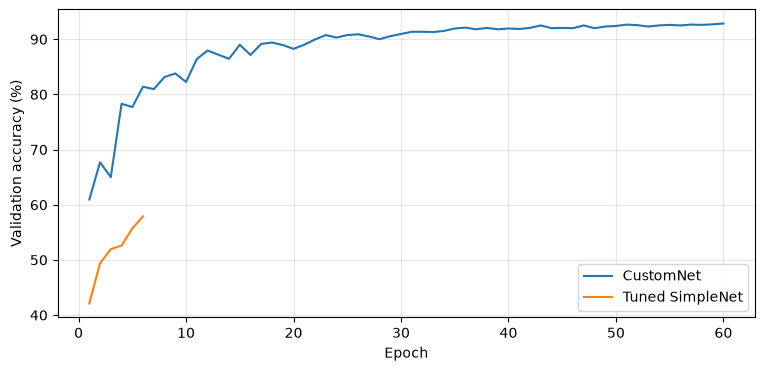

In [11]:
class ResidualBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(channels, channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(channels), nn.ReLU(),
            nn.Conv2d(channels, channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(channels))
    def forward(self, x):
        return F.relu(x + self.layers(x))

class CustomNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 64, 3, padding=1, bias=False), nn.BatchNorm2d(64), nn.ReLU(),
            ResidualBlock(64), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1, bias=False), nn.BatchNorm2d(128), nn.ReLU(),
            ResidualBlock(128), nn.MaxPool2d(2),
            nn.Conv2d(128, 256, 3, padding=1, bias=False), nn.BatchNorm2d(256), nn.ReLU(),
            ResidualBlock(256), nn.AdaptiveAvgPool2d(1))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(0.2), nn.Linear(256, 10))
    def forward(self, x):
        return self.classifier(self.features(x))

cifar_augmentation = transforms.Compose([
    transforms.RandomCrop(32, padding=4), transforms.RandomHorizontalFlip(),
    transforms.ToTensor(), transforms.Normalize((0.5,)*3, (0.5,)*3),
    transforms.RandomErasing(p=0.15, scale=(0.02, 0.15), value=0)])
cifar_aug_train = torchvision.datasets.CIFAR10(root=str(DATA_ROOT), train=True,
                                             download=False, transform=cifar_augmentation)
optimizer_params_custom = {'lr': 1e-3, 'weight_decay': 5e-4}
CUSTOM_EPOCHS = 60

# Equal six-epoch comparison: same augmentation, label smoothing, optimizer and LR schedule.
seed_all()
model_tuned_simple = to_device(SimpleNet())
tuned_simple_history = train_and_test(
    model_tuned_simple, 6, make_loader(cifar_aug_train, 128, True), cifar_val_loader,
    optimizer=optim.AdamW, optimizer_params=optimizer_params_custom,
    cosine_epochs=CUSTOM_EPOCHS, label_smoothing=0.05)
seed_all()
model_custom = to_device(CustomNet())
custom_history = train_and_test(
    model_custom, CUSTOM_EPOCHS, make_loader(cifar_aug_train, 128, True), cifar_val_loader,
    optimizer=optim.AdamW, optimizer_params=optimizer_params_custom,
    cosine_epochs=CUSTOM_EPOCHS, label_smoothing=0.05)
metrics['tuned_simple_history'] = tuned_simple_history
metrics['custom_history'] = custom_history
metrics['custom_parameters'] = sum(p.numel() for p in model_custom.parameters())
save_metrics()
plt.figure(figsize=(9, 4))
plt.plot([h['epoch'] for h in custom_history], [h['accuracy'] for h in custom_history], label='CustomNet')
plt.plot([h['epoch'] for h in tuned_simple_history], [h['accuracy'] for h in tuned_simple_history], label='Tuned SimpleNet')
plt.xlabel('Epoch'); plt.ylabel('Validation accuracy (%)'); plt.legend(); plt.grid(alpha=0.3)
plt.show()


After you are done tuning the architecture structure and the hyperparameters, report your results with both CustomNet and SimpleNet on the `test_minus_val` split below. Discuss your resulting architecture in Discussion 1 below.

In [12]:
accuracy_simple = test(model_simple, cifar_test_minus_val_loader)
accuracy_tuned_simple = test(model_tuned_simple, cifar_test_minus_val_loader)
accuracy_custom = test(model_custom, cifar_test_minus_val_loader)
print(f'Baseline model accuracy (test_minus_val): {accuracy_simple:.2f}%')
print(f'Tuned SimpleNet accuracy (test_minus_val): {accuracy_tuned_simple:.2f}%')
print(f'Custom model accuracy (test_minus_val): {accuracy_custom:.2f}%')
print(f'Improvement: {accuracy_custom - accuracy_simple:.2f} percentage points')
metrics['cifar_test'] = {'baseline': accuracy_simple, 'tuned_simple': accuracy_tuned_simple,
                       'custom': accuracy_custom}
save_metrics()
for name, model in [('simple',model_simple), ('custom',model_custom)]:
    torch.save(model.state_dict(), ARTIFACT_ROOT / f'{name}.pt')


Baseline model accuracy (test_minus_val): 47.29%
Tuned SimpleNet accuracy (test_minus_val): 57.26%
Custom model accuracy (test_minus_val): 92.61%
Improvement: 45.32 percentage points


### Discussion 1
Describe your final architecture and training setup (layers, normalization, optimizer, learning rate, epochs). Which change gave you the largest improvement?

CustomNet uses nine 3×3 convolutions in 64/128/256-channel stages, three residual blocks, BatchNorm and ReLU, two max-pooling layers, global average pooling, dropout (0.2), and a 10-class linear head (1,923,914 parameters). I trained it for 60 epochs with AdamW (initial learning rate 0.001, weight decay 0.0005), cosine decay, batch size 128, random padded crops and horizontal flips, random erasing (probability 0.15), and label smoothing (0.05); the best checkpoint was selected using the 2,000-image validation split. On the separate 8,000-image test split it achieved **92.61%**, compared with **47.29%** for the provided two-epoch SGD baseline and 57.26% for tuned SimpleNet. In the matched six-epoch runs, CustomNet reached 81.40% validation accuracy versus 57.90% for SimpleNet (a 23.50-point gain); additional CustomNet epochs added 11.45 points, so the architecture change gave the larger measured gain. The earlier 30-epoch configuration achieved 91.36% test accuracy; this revised training recipe achieved 92.61%. Because that test split was already evaluated, it is not a newly untouched holdout. These experiments do not isolate the effects of BatchNorm, residual connections, and width individually; the baseline also follows the template in evaluating on the full CIFAR test set during its fixed two epochs.

# 3. Dogs-vs-Cats and model tuning

Let's now explore some images with higher resolution than those of 32x32 from CIFAR. One of the popular classification datasets is ["Dogs vs Cats"](https://www.kaggle.com/c/dogs-vs-cats/data). We will use a smaller version of the dataset here, picking 2000 images subset for training. Let's download and extract the archive to the /tmp folder.

Loaded 2000 training and 1000 validation images.


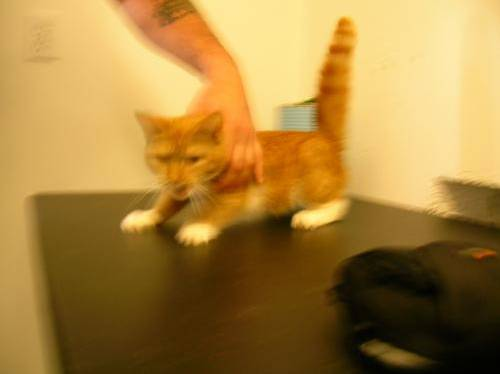

In [13]:
dataset_url = 'https://storage.googleapis.com/tensorflow-1-public/course2/cats_and_dogs_filtered.zip'
local_zip = DATA_ROOT / 'cats_and_dogs_filtered.zip'
if not local_zip.exists():
    urllib.request.urlretrieve(dataset_url, local_zip)
if not zipfile.is_zipfile(local_zip):
    raise RuntimeError(f'Invalid ZIP: {local_zip}')
with zipfile.ZipFile(local_zip) as zip_ref:
    assert zip_ref.testzip() is None, 'Corrupt archive'
    if not (DATA_ROOT / 'cats_and_dogs_filtered/train').exists():
        zip_ref.extractall(DATA_ROOT)
CATDOG_ROOT = DATA_ROOT / 'cats_and_dogs_filtered'
train_data = ImageFolder(str(CATDOG_ROOT / 'train'))
validation_data = ImageFolder(str(CATDOG_ROOT / 'validation'))
assert train_data.classes == validation_data.classes == ['cats','dogs']
assert len(train_data) == 2000 and len(validation_data) == 1000
print(f'Loaded {len(train_data)} training and {len(validation_data)} validation images.')
display(train_data[0][0])


Let's see how our simple (or your custom) model trained on CIFAR does on these images. For this one, mine predicted a `truck` class as a top prediction with 41.3% confidence. If yours predicted a cat: great! But how does it do on other images? Try a few more changing the `sample_idx` below.

frog: 33.9%


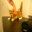

In [14]:
def get_prediction(img, model, preprocess=None, class_names=None):
    batch = preprocess(img) if preprocess is not None else img
    batch = batch.unsqueeze(0)
    batch = to_device(batch)
    model.eval()
    with torch.no_grad():
        prediction = model(batch).squeeze(0).softmax(0)
    class_id = prediction.argmax().item()
    score = prediction[class_id].item()
    category_name = class_names[class_id] if class_names is not None else class_id
    return category_name, score


def get_class_score(img, model, preprocess, class_id):
    """Probability of a *specific* class (not the winning one) for a single image."""
    batch = to_device(preprocess(img).unsqueeze(0))
    model.eval()
    with torch.no_grad():
        return model(batch).squeeze(0).softmax(0)[class_id].item()

sample_idx = 0
img = train_data[sample_idx][0]
img = img.resize((32, 32))
category_name, score = get_prediction(
    img, model_simple, preprocess, cifar_train.classes)
print(f"{category_name}: {100 * score:.1f}%")
img


## Fine tuning

Fine-tuning is the process of taking a strong pre-trained model and adapting it to a new dataset by training it further. Our pre-trained model is a 50-layer ResNet architecture, trained on the large ImageNet dataset to distinguish between 1000 classes.

Fine-tuning involves freezing the weights of the lower layers in the pre-trained model, which are responsible for low-level features such as edges and textures, and training the upper layers on the new dataset. The weights in the upper layers are initialized randomly and then updated through backpropagation during training.

We want to leverage the features of the ResNet and consider an extreme case, when all the layers are frozen, except for the last linear (fully connected) layer.

In [15]:
# Imagenet accuracy: 80.858%
weights=ResNet50_Weights.DEFAULT
model_resnet = resnet50(weights=weights)
model_resnet = to_device(model_resnet)

ImageNet doesn't have a simple `cat` class: it rather has several classes such as `Egyptian cat`, `tabby cat`, etc. Assigning a cat to a wrong breed is considered the same as assigning a completely unrelated label. For example `sample_idx=3` is assigned to a `lynx` label (reasonable?), while `sample_idx=40` is assigned a `chihuahua` label as cats don't fall under the ImageNet specific breeds.

tabby: 20.6%


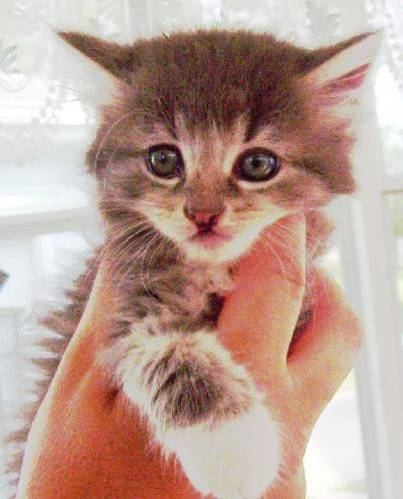

In [16]:
sample_idx = 3
img = train_data[sample_idx][0]
category_name, score = get_prediction(img, model_resnet, weights.transforms(),
                                      weights.meta["categories"])
print(f"{category_name}: {100 * score:.1f}%")
img

## TODO #3 (5 points): Fine-tune the ResNet

Let's fine-tune the pre-trained ResNet. This involves the following steps:
1. freeze the pretrained layers;
2. modify the output to match the Dogs-vs-Cats class: you can simply change the `model_resnet.fc` output layer: there's no need to write new classes (e.g. if you wanted the last layer to be a convolution, you could re-define it as `model_resnet.fc = nn.Conv2D(3, 4, 5)`);
3. run `train_and_test` with appropriate arguments.

Can you achieve high accuracy now? Record the test accuracy and the time per epoch: you will compare them with a Vision Transformer in the next part.

In [17]:
# Dogs-vs-Cats train and test sets
train_transforms = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

test_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])
catsdogs_train = ImageFolder(str(CATDOG_ROOT / 'train'), transform=train_transforms)
catsdogs_test = ImageFolder(str(CATDOG_ROOT / 'validation'), transform=test_transforms)
catsdogs_train_loader = torch.utils.data.DataLoader(
    catsdogs_train, batch_size=32, shuffle=True, num_workers=0)
catsdogs_test_loader = torch.utils.data.DataLoader(
    catsdogs_test, batch_size=32, shuffle=False, num_workers=0)

# Freeze the parameters
for param in model_resnet.parameters():
    param.requires_grad = False



model_resnet.fc = nn.Linear(model_resnet.fc.in_features, 2)
model_resnet = to_device(model_resnet)
FINETUNE_EPOCHS = 5
seed_all()
resnet_history = train_and_test(model_resnet, FINETUNE_EPOCHS,
    catsdogs_train_loader, catsdogs_test_loader,
    optimizer=optim.AdamW, optimizer_params={'lr': 1e-3, 'weight_decay': 1e-4},
    frozen_backbone=True)
resnet_accuracy = test(model_resnet, catsdogs_test_loader)
metrics['resnet'] = {'history': resnet_history, 'accuracy':resnet_accuracy,
    'mean_epoch_time': float(np.mean([h['train_time'] for h in resnet_history]))}
save_metrics()
torch.save(model_resnet.state_dict(), ARTIFACT_ROOT / 'resnet_catsdogs.pt')


Epoch 1/5: loss=0.2381, eval accuracy=99.50%, training time=7.28s
Epoch 2/5: loss=0.0975, eval accuracy=99.50%, training time=6.09s
Epoch 3/5: loss=0.0754, eval accuracy=99.50%, training time=6.28s
Epoch 4/5: loss=0.0645, eval accuracy=99.50%, training time=6.12s
Epoch 5/5: loss=0.0668, eval accuracy=99.50%, training time=6.06s
Restored best evaluation checkpoint: 99.50%


## Fine tuning a Vision Transformer

Convolutional networks are not the only option for a backbone. Vision Transformers (ViT) split the image into fixed-size patches (here 16x16 pixels), embed each patch as a token, and process the sequence of tokens with a standard Transformer encoder, the same architecture used in language models. A special `[CLS]` token summarizes the whole image and feeds the classification head.

We use `vit_small_patch16_224` from the `timm` library (about 22M parameters, pre-trained on ImageNet), which is comparable in size to ResNet-50 (about 25M parameters). Note that this model expects a **different input normalization** from the ResNet (mean and std of 0.5), so we build the transforms from the model's own data configuration instead of reusing the ResNet ones.

## TODO #4 (5 points): Fine-tune the ViT and compare with ResNet-50

Repeat the fine-tuning procedure with the ViT:
1. freeze the pretrained layers;
2. modify the output to match the Dogs-vs-Cats classes: change the `model_vit.head` layer (`model_vit.head.in_features` gives the input size);
3. run `train_and_test` with the same number of epochs as for the ResNet.

Then fill in the comparison table in Discussion 2.

In [18]:
try:
    import timm
except ImportError:
    !pip install -q timm
    import timm

model_vit = timm.create_model("vit_small_patch16_224", pretrained=True)
model_vit = to_device(model_vit)

# Build the transforms that match this model's pre-training
vit_config = timm.data.resolve_data_config({}, model=model_vit)
print(vit_config)
vit_test_transforms = timm.data.create_transform(**vit_config, is_training=False)
vit_train_transforms = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(vit_config["mean"], vit_config["std"])
])

catsdogs_train_vit = ImageFolder(str(CATDOG_ROOT / 'train'), transform=vit_train_transforms)
catsdogs_test_vit = ImageFolder(str(CATDOG_ROOT / 'validation'), transform=vit_test_transforms)
catsdogs_train_vit_loader = torch.utils.data.DataLoader(
    catsdogs_train_vit, batch_size=32, shuffle=True, num_workers=0)
catsdogs_test_vit_loader = torch.utils.data.DataLoader(
    catsdogs_test_vit, batch_size=32, shuffle=False, num_workers=0)

# Freeze the parameters
for param in model_vit.parameters():
    param.requires_grad = False


model_vit.head = nn.Linear(model_vit.head.in_features, 2)
model_vit = to_device(model_vit)
seed_all()
vit_history = train_and_test(model_vit, FINETUNE_EPOCHS,
    catsdogs_train_vit_loader, catsdogs_test_vit_loader,
    optimizer=optim.AdamW, optimizer_params={'lr': 1e-3, 'weight_decay': 1e-4},
    frozen_backbone=True)
vit_accuracy = test(model_vit, catsdogs_test_vit_loader)
metrics['vit'] = {'history': vit_history, 'accuracy': vit_accuracy,
    'mean_epoch_time': float(np.mean([h['train_time'] for h in vit_history]))}
save_metrics()
torch.save(model_vit.state_dict(), ARTIFACT_ROOT / 'vit_catsdogs.pt')


C:\Users\derpi\Documents\Codex\2026-10-14\referenced-chatgpt-conversation-this-is-an\work\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'input_size': (3, 224, 224), 'interpolation': 'bicubic', 'mean': (0.5, 0.5, 0.5), 'std': (0.5, 0.5, 0.5), 'crop_pct': 0.9, 'crop_mode': 'center'}
Epoch 1/5: loss=0.1348, eval accuracy=99.50%, training time=5.76s
Epoch 2/5: loss=0.0410, eval accuracy=99.90%, training time=5.77s
Epoch 3/5: loss=0.0403, eval accuracy=99.70%, training time=5.80s
Epoch 4/5: loss=0.0308, eval accuracy=99.90%, training time=5.87s
Epoch 5/5: loss=0.0289, eval accuracy=99.90%, training time=6.66s
Restored best evaluation checkpoint: 99.90%


In [19]:
# Count trainable vs. total parameters for both models
def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

for name, m in [("ResNet-50", model_resnet), ("ViT-Small", model_vit)]:
    total, trainable = count_params(m)
    print(f"{name}: {total/1e6:.1f}M total, {trainable/1e3:.1f}K trainable")
for name,m in [('resnet', model_resnet), ('vit', model_vit)]:
    total,trainable = count_params(m)
    metrics[name].update(total_parameters=total,trainable_parameters=trainable)
save_metrics()


ResNet-50: 23.5M total, 4.1K trainable
ViT-Small: 21.7M total, 0.8K trainable


### Discussion 2
Fill in the table and answer the question.

Which backbone worked better here, and by how much (accuracy and time)? Name one plausible reason for the difference (think about pre-training data, the inductive biases of convolutions vs. attention, or the fixed-feature setting).

| Model | Total params | Trainable params | Test accuracy | Time / epoch |
|---|---:|---:|---:|---:|
| ResNet-50 (frozen + new fc) | 23,512,130 | 4,098 | 99.50% | 6.36 s |
| ViT-Small (frozen + new head) | 21,666,434 | 770 | 99.90% | 5.97 s |

ViT-Small was more accurate by 0.40 percentage points, while ViT-Small trained faster by 0.39 seconds per epoch. Both used five epochs of AdamW at 0.001, the same images and augmentation, model-specific normalization, and a frozen backbone kept in evaluation mode; times are the mean training-only wall-clock times, including data loading. This ViT checkpoint was pre-trained on ImageNet-21k before fine-tuning on ImageNet-1k, which may provide more transferable fixed features here ([model card](https://huggingface.co/timm/vit_small_patch16_224.augreg_in21k_ft_in1k)). This is a hypothesis rather than an isolated architectural test, and the reported accuracies use the best of five checkpoints on the assignment’s 1,000-image validation/test set.

## 4. Beyond image classification

So far we looked only at the image classification task, which seems like a very narrow (and easy?) problem. But in fact, image classification networks are used as a core (backbone) for most of the image recognition problems.

Our fine-tuned network distinguishes cats from dogs, but it also gives us its prediction confidence. Let's try to use this confidence to add (some) localization capabilities to the network.

Object localization, or object detection involves modifying the network architecture to output both a class label for the input image and a bounding box that specifies the location of the object in the image. We won't build a complete detector, but we will make a step towards creating a region proposal network that says how likely a selected region contains an object of interest.

Imagine that you know the size of the object you are looking for. For instance, in the image below, assume you know that you look for objects that occupy about 3% of the image that fit into a square of size $K \times K$. For the image below, that would mean that the square has a side of $K = 170$ pixels. Let's see what confidence our network has for a random patch of size $K \times K$ and for a patch that is centered on the dog. Note that we ask for the probability of the `dog` class specifically (`get_class_score`), not the probability of whichever class wins: a patch that is confidently classified as `cat` is *not* a good dog proposal.

This may sound counterintuitive from the first glance that this process has any meaning. Our network can only predict `cat` or `dog` class, and we are asking it to classify a patch of the sky or forest! However, the fact that the network doesn't see any cat or dog features in the patch will hopefully push it towards predicting the corresponding class with a lower confidence.

Localization image size: (800, 1066)


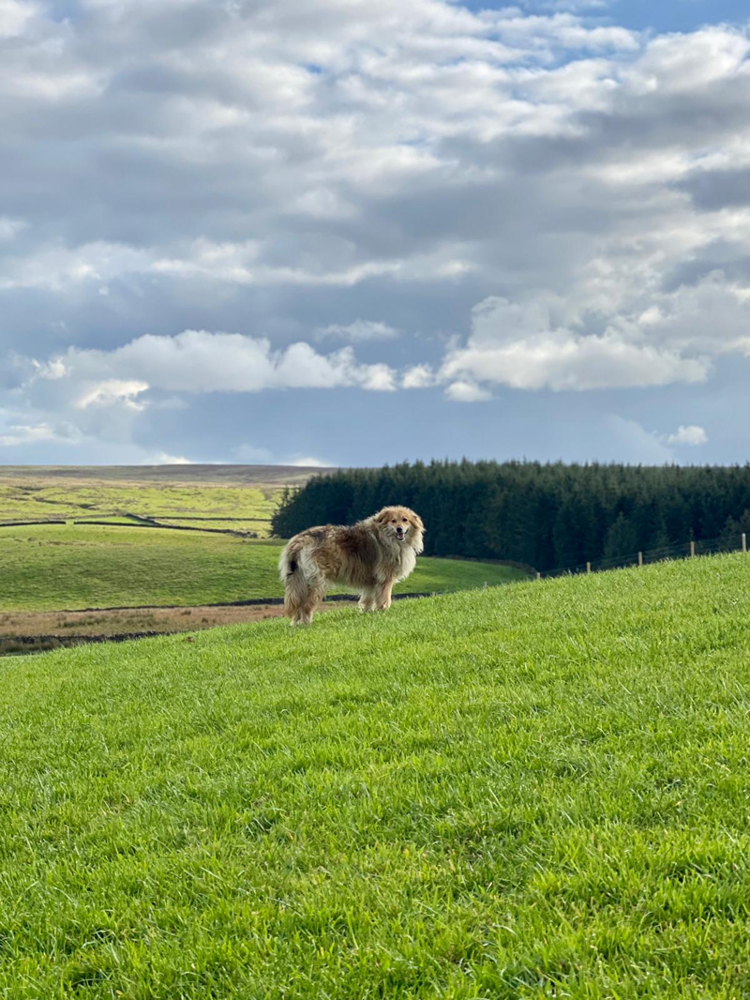

In [20]:
localize_path = DATA_ROOT / 'localize.jpeg'
if not localize_path.exists():
    urllib.request.urlretrieve('https://www.blossomsfield.co.uk/wp-content/uploads/2020/10/WhatsApp-Image-2020-10-06-at-12.43.20.jpeg', localize_path)
img = Image.open(localize_path).convert('RGB')
width, height = img.size
img = img.resize((800, int(height * 800 / width)))
print('Localization image size:', img.size)
display(img)


P(dog) = 87.8%


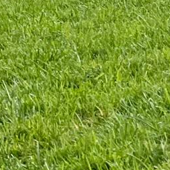

In [21]:
# Running our fine-tuned ResNet on a background patch.
dog_class_id = catsdogs_test.classes.index("dogs")

left = 35
upper = 740
size = 170
box_random = (left, upper, left + size, upper + size)
crop_random = img.crop(box_random)
score_random = get_class_score(crop_random, model_resnet, test_transforms, dog_class_id)
print(f"P(dog) = {100 * score_random:.1f}%")
crop_random

P(dog) = 96.8%


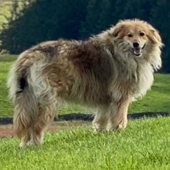

In [22]:
# Running our fine-tuned ResNet on a dog patch.
left = 290
upper = 520
size = 170
box_center = (left, upper, left + size, upper + size)
crop_center = img.crop(box_center)
score_center = get_class_score(crop_center, model_resnet, test_transforms, dog_class_id)
print(f"P(dog) = {100 * score_center:.1f}%")
crop_center

Use the function below to draw a set of patches on top of the image.

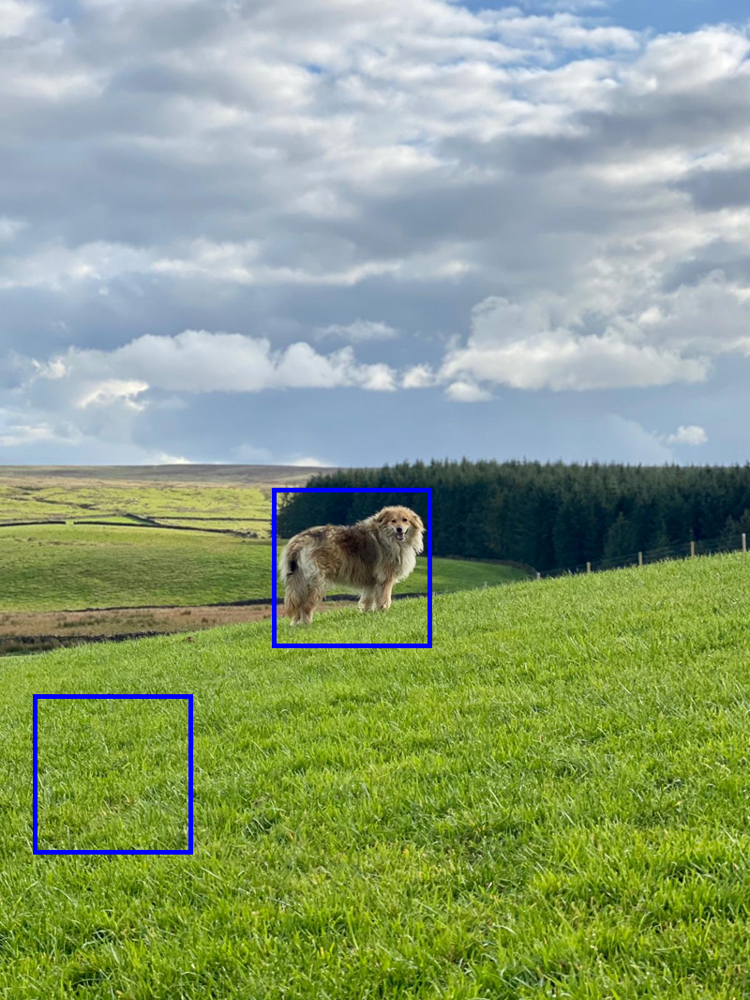

In [23]:
def draw(boxes, scores, color=(255, 0, 0)):
    width, height = img.size
    nboxes = len(boxes)
    pad = 10
    im2show = img.copy()
    img_draw = ImageDraw.Draw(im2show)
    for i, box in enumerate(boxes):
        score = scores[i]
        img_draw.rectangle(box, outline=color, width=5)

    return im2show

boxes = [box_center, box_random]
scores = [score_center, score_random]
im2show = draw(boxes, scores, color="blue")
im2show

## TODO #5 (5 points): Implement the sliding window and visualize the most and the least confident predictions

Let's produce a set of candidates in a sliding window fashion. That is, place a window of size $K \times K$ into the top left corner, and evaluate the score of the corresponding crop to contain class `dog`. Now slide this window across all possible locations with step $s$ (i.e. evaluate a crop of size $K \times K$ with the top left corner coordinate $(0, s)$ next). Record all window positions and the corresponding scores for the `dog` class. Then sort them and plot top-20 and bottom-20 scoring ones. Pick $s$ yourself, and $K = 170$. Use the probability of the `dog` class for every crop (`get_class_score`, or batch the crops and take `softmax(...)[:, dog_class_id]`), **not** the confidence of the predicted class.

In [24]:
def window_positions(length, size, stride):
    if length < size:
        raise ValueError('Window larger than image')
    positions = list(range(0, length-size+1, stride))
    if positions[-1] != length-size:
        positions.append(length-size)
    return positions

def sliding_window(image, model, transform, class_id, size=170, stride=40, batch=32):
    all_boxes = [(x,y,x+size,y+size)
                 for y in window_positions(image.height,size,stride)
                 for x in window_positions(image.width,size,stride)]
    all_scores = []
    model.eval()
    model_device = next(model.parameters()).device
    with torch.no_grad():
        for start in range(0,len(all_boxes),batch):
            inputs = torch.stack([transform(image.crop(b))
                                  for b in all_boxes[start:start+batch]]).to(model_device)
            with torch.autocast(device_type=model_device.type,
                                enabled=model_device.type == 'cuda'):
                logits = model(inputs)
            all_scores.extend(logits.float().softmax(1)[:,class_id].cpu().tolist())
    order = sorted(range(len(all_boxes)), key=lambda i:all_scores[i], reverse=True)
    return [all_boxes[i] for i in order], [all_scores[i] for i in order]

# Warm up the entire approach; timed run includes crop transforms, transfers and sorting.
sliding_window(img, model_resnet, test_transforms, dog_class_id)
synchronize()
t0 = time.perf_counter()
boxes, scores = sliding_window(img, model_resnet, test_transforms, dog_class_id)
synchronize()
sliding_time = time.perf_counter()-t0
sliding_calls = int(np.ceil(len(boxes)/32))
print(f'Sliding window: {len(boxes)} crops, {sliding_calls} batched forward calls, {sliding_time:.4f}s')
print('Top dog probability:', scores[0], 'Bottom:', scores[-1])
metrics['sliding'] = {'time':sliding_time, 'crops':len(boxes), 'calls':sliding_calls,
                      'stride':40, 'size':170, 'boxes':boxes, 'scores':scores}
save_metrics()


Sliding window: 408 crops, 13 batched forward calls, 0.7874s
Top dog probability: 0.9782395958900452 Bottom: 0.6097565293312073


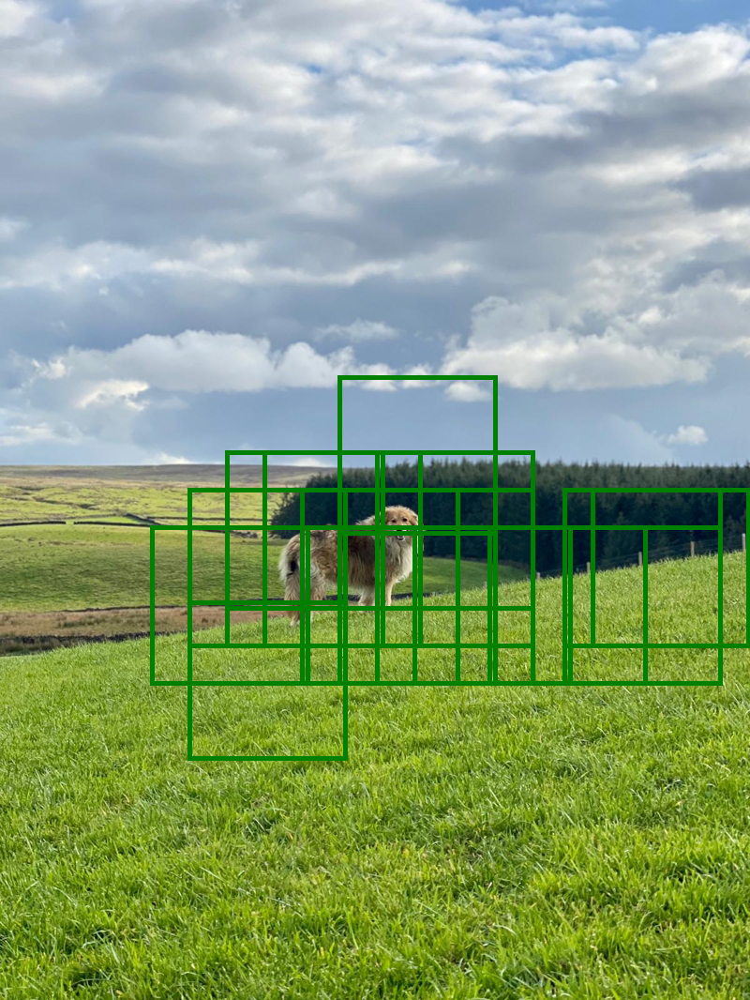

In [25]:
# Visualize the top-20 scoring boxes
high_scoring_img = draw(boxes[:20], scores[:20], color="green")
high_scoring_img
high_scoring_img.save(ARTIFACT_ROOT / 'top20.png')
display(high_scoring_img)


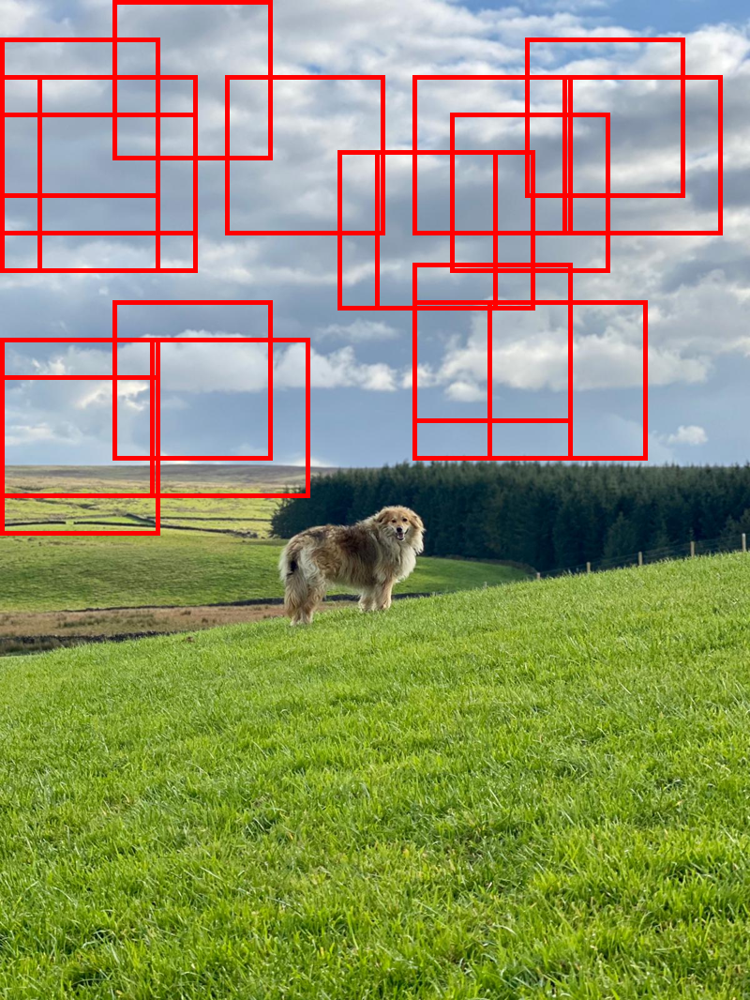

In [26]:
# Visualize the bottom-20 scoring boxes
low_scoring_img = draw(boxes[-20:], scores[-20:], color="red")
low_scoring_img
low_scoring_img.save(ARTIFACT_ROOT / 'bottom20.png')
display(low_scoring_img)


Discuss your results: where did the top-20 scoring boxes land? How about the bottom-20 ones? Do any of the low scoring boxes still contain any pixels belonging to the dog? Why might that be (i.e. why a set of pixels belonging to the dog may score lower than a corner box with just the sky or just the grass)?

### Discussion 3
The top-20 boxes spread across the grass and forest around the dog, with several covering the animal but many covering only background; the highest-scoring box includes part of the dog’s rear body and legs, misses its head, and contains substantial grass. The bottom-20 boxes mostly cover sky, with a few extending into the distant fields, and none visibly includes dog pixels. Even the minimum dog probability is 61.0%, and the example background crop scores 87.8%, so this binary cat/dog classifier is clearly not a calibrated foreground detector. A crop containing only a tail or legs could score below a background crop because it loses the diagnostic features of a complete dog, resizing changes the apparent texture, and the classifier has never learned a “neither cat nor dog” class.

## 4.2 Comparing with a modern object detector: YOLO

Our sliding window is a crude version of what detectors did a decade ago. Modern detectors like **YOLO** ("You Only Look Once") run the backbone once on the whole image and predict boxes and classes for all objects in a single forward pass, at many scales and aspect ratios, in a fraction of a second.

Let's run a pre-trained YOLO model (YOLOv8s, trained on the COCO dataset, which includes a `dog` class) on the same image and compare it with our region proposals.

## TODO #6 (5 points): Run YOLO and compare it with your region proposals

1. Run YOLOv8s on the image (done for you below) and draw its `dog` detection(s) on the image together with your top-1 sliding-window box.
2. Implement `iou()` (intersection over union) and compute the IoU between YOLO's highest-confidence `dog` box (or its highest-confidence box overall, if it did not call the dog a `dog`) and (a) your top-1 sliding-window box, (b) the best IoU among your top-20 boxes.
3. Time both approaches: the wall-clock time of a warmed-up run of your sliding window (all crops, model already on the device) vs. a warmed-up YOLO call on the full image (done for you below). Report both numbers together with how many crops the sliding window evaluated (and in how many batched forward calls) versus the single full-image pass of YOLO.

YOLO: one full-image pass, wall-clock time 0.0217s
dog        0.8925 (296.5, 539.2, 454.2, 669.3)


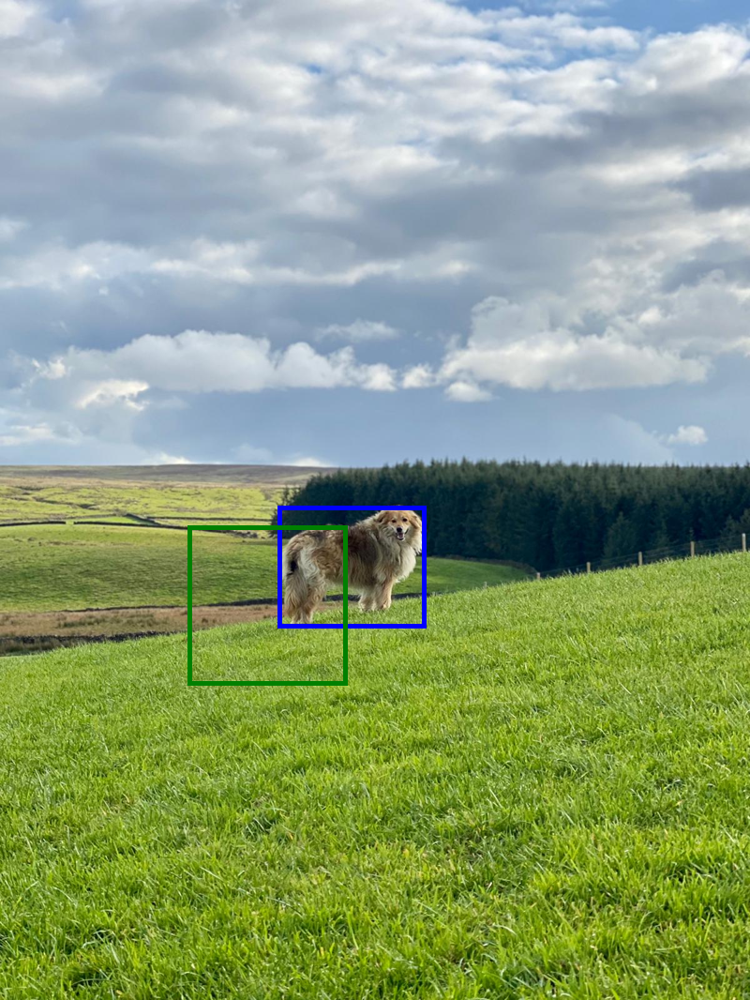

In [27]:
from ultralytics import YOLO
model_yolo = YOLO('yolov8s.pt')
yolo_device = 0 if torch.cuda.is_available() else 'cpu'
model_yolo(img, verbose=False, conf=0.1, device=yolo_device)
synchronize()
t0 = time.perf_counter()
results = model_yolo(img, verbose=False, conf=0.1, device=yolo_device)
synchronize()
yolo_time = time.perf_counter()-t0
print(f'YOLO: one full-image pass, wall-clock time {yolo_time:.4f}s')
yolo_boxes, yolo_scores, yolo_names = [], [], []
for r in results:
    for b in r.boxes:
        yolo_boxes.append(tuple(b.xyxy[0].tolist()))
        yolo_scores.append(float(b.conf[0]))
        yolo_names.append(r.names[int(b.cls[0])])
for box,s,n in zip(yolo_boxes,yolo_scores,yolo_names):
    print(f'{n:10s} {s:.4f} {tuple(round(v,1) for v in box)}')
dog_indices = [i for i,name in enumerate(yolo_names) if name == 'dog']
display_indices = dog_indices if dog_indices else list(range(len(yolo_boxes)))
im2show = draw([yolo_boxes[i] for i in display_indices],
               [yolo_scores[i] for i in display_indices], color='blue')
ImageDraw.Draw(im2show).rectangle(boxes[0], outline='green', width=5)
im2show.save(ARTIFACT_ROOT / 'yolo_comparison.png')
display(im2show)


In [28]:
def iou(box_a, box_b):
    left, top = max(box_a[0],box_b[0]), max(box_a[1],box_b[1])
    right, bottom = min(box_a[2],box_b[2]), min(box_a[3],box_b[3])
    intersection = max(0,right-left)*max(0,bottom-top)
    area_a = max(0,box_a[2]-box_a[0])*max(0,box_a[3]-box_a[1])
    area_b = max(0,box_b[2]-box_b[0])*max(0,box_b[3]-box_b[1])
    union = area_a+area_b-intersection
    return intersection/union if union > 0 else 0.0

assert iou((0,0,10,10),(0,0,10,10)) == 1.0
assert iou((0,0,1,1),(2,2,3,3)) == 0.0
assert abs(iou((0,0,2,2),(1,1,3,3))-1/7) < 1e-9
assert iou((0,0,0,0),(0,0,0,0)) == 0.0
if not yolo_boxes:
    raise RuntimeError('YOLO returned no detections; lower the threshold and inspect the image')
candidates = dog_indices or list(range(len(yolo_boxes)))
selected = max(candidates, key=lambda i:yolo_scores[i])
reference_box = yolo_boxes[selected]
top1_iou = iou(boxes[0], reference_box)
best20_iou = max(iou(b, reference_box) for b in boxes[:20])
print('YOLO reference class:', yolo_names[selected], '(fallback:', not bool(dog_indices), ')')
print(f'Top-1 IoU: {top1_iou:.4f}; best top-20 IoU: {best20_iou:.4f}')
print(f'Sliding: {sliding_time:.4f}s / {len(boxes)} crops / {sliding_calls} batches; '
      f'YOLO: {yolo_time:.4f}s / one full-image pass')
metrics['yolo'] = {'time':yolo_time, 'boxes':yolo_boxes, 'scores':yolo_scores,
    'names':yolo_names, 'selected':selected, 'fallback':not bool(dog_indices),
    'top1_iou':top1_iou, 'best20_iou':best20_iou}
save_metrics()


YOLO reference class: dog (fallback: False )
Top-1 IoU: 0.1941; best top-20 IoU: 0.6782
Sliding: 0.7874s / 408 crops / 13 batches; YOLO: 0.0217s / one full-image pass


### Discussion 4
How well does your sliding-window proposal agree with YOLO (report the IoUs and the timings)? What drawbacks does the sliding-window approach of creating region proposals have, and which of them does a detector like YOLO address (think about object size, aspect ratio, speed, and what happens when there are several objects)? What extra steps would you need to turn your region proposal net into a real detector?

YOLO identified the reference as dog. The top-1 sliding-window IoU was **0.1941**, and the best IoU among the top 20 proposals was **0.6782**; these measure agreement with YOLO, not accuracy against manually annotated ground truth. The warmed-up sliding window took **0.7874 s** for **408 crops in 13 batched forward calls**, whereas YOLO took **0.0217 s** for one full-image pass (same GPU, synchronized wall-clock timing). A fixed 170×170 square cannot adapt to object size or aspect ratio, adjacent proposals overlap heavily, and independently classifying every crop repeats computation and can miss or confuse multiple objects. YOLO shares full-image features and predicts class-specific boxes at several scales with suppression of duplicate detections. A real detector would require bounding-box training annotations, background/objectness supervision, box regression, multiple scales and aspect ratios, and non-maximum suppression.

# 5. Generative models: text-to-image diffusion

**This section requires a GPU runtime** (`Runtime -> Change runtime type -> T4 GPU`). Each image takes a few seconds on a T4; the whole section should take about 10-15 minutes. If your session runs out, re-run only this section: it does not depend on the earlier ones.

So far our networks took an image as input and produced a label or a box. Generative models go the other way: they produce an image. Diffusion models generate an image by starting from pure Gaussian noise and iteratively denoising it, guided by a text prompt. Three things affect the result:

* **The initial noise** (set by the random seed). The same prompt with different seeds gives different images.
* **The number of denoising steps** (e.g. with the DDIM sampler). Fewer steps are faster but may lower the quality.
* **The model itself.** Models differ in size, training data, and training objective.

We use the `diffusers` library and two small models that fit on a free Colab GPU in half precision:

* `stable-diffusion-v1-5/stable-diffusion-v1-5` (Stable Diffusion v1.5, about 0.9B parameters, 512x512 images) with a DDIM scheduler;
* `stabilityai/sd-turbo` (SD-Turbo, a distilled model that produces an image in 1-4 steps without classifier-free guidance).

**Content note:** pick neutral prompts (objects, animals, landscapes, scenes). Prompts that name real people or contain sensitive content will not be graded.

In [29]:
# This section can also run independently after installing the packages.
import gc, time, json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
from diffusers import StableDiffusionPipeline, AutoPipelineForText2Image, DDIMScheduler
assert torch.cuda.is_available(), 'Section 5 needs a CUDA GPU.'
device = 'cuda'
ARTIFACT_ROOT = Path('homework_data/experiment_artifacts')
ARTIFACT_ROOT.mkdir(parents=True, exist_ok=True)
if 'metrics' not in globals():
    metrics = {}
def save_metrics():
    (ARTIFACT_ROOT / 'metrics.json').write_text(json.dumps(metrics, indent=2))
# Release classifier VRAM before loading diffusion; retained CPU models are no longer used.
for name in ['model_simple','model_custom','model_tuned_simple','model_resnet','model_vit']:
    if name in globals():
        globals()[name].cpu()
if 'model_yolo' in globals():
    model_yolo.model.cpu()
gc.collect()
torch.cuda.empty_cache()
pipe_sd = StableDiffusionPipeline.from_pretrained(
    'stable-diffusion-v1-5/stable-diffusion-v1-5',
    torch_dtype=torch.float16, variant='fp16', safety_checker=None)
pipe_sd.scheduler = DDIMScheduler.from_config(pipe_sd.scheduler.config)
pipe_sd = pipe_sd.to(device)
# PyTorch scaled-dot-product attention is memory efficient on this 8 GB GPU.
pipe_sd.enable_vae_slicing()
pipe_sd.set_progress_bar_config(disable=True)
print('SD v1.5 loaded:', type(pipe_sd.scheduler).__name__, torch.cuda.get_device_name(0))


Loading pipeline components...: 100%|██████████| 6/6 [00:00<00:00, 13.77it/s]
You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


SD v1.5 loaded: DDIMScheduler NVIDIA GeForce RTX 3060 Ti


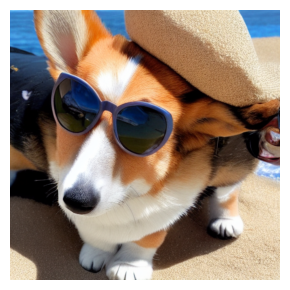

In [30]:
def generate(pipe, prompt, seed, num_steps=25, guidance_scale=7.5, size=512):
    g = torch.Generator(device='cuda').manual_seed(seed)
    with torch.inference_mode():
        return pipe(prompt, num_inference_steps=num_steps, guidance_scale=guidance_scale,
                    height=size, width=size, generator=g).images[0]

def timed_generate(pipe, prompt, seed, num_steps=25, guidance_scale=7.5):
    torch.cuda.synchronize()
    t0 = time.perf_counter()
    image = generate(pipe,prompt,seed,num_steps,guidance_scale)
    torch.cuda.synchronize()
    return image, time.perf_counter()-t0

def show_grid(images, titles=None, ncols=None, figsize_per_img=3, filename=None):
    ncols = ncols or len(images)
    nrows = int(np.ceil(len(images)/ncols))
    fig, axes = plt.subplots(nrows,ncols,figsize=(figsize_per_img*ncols,figsize_per_img*nrows))
    for i,ax in enumerate(np.array(axes).reshape(-1)):
        ax.axis('off')
        if i < len(images):
            ax.imshow(images[i])
            if titles:
                ax.set_title(titles[i],fontsize=9)
    plt.tight_layout()
    if filename:
        fig.savefig(ARTIFACT_ROOT / filename, dpi=140, bbox_inches='tight')
    plt.show()
    plt.close(fig)

show_grid([generate(pipe_sd,'a photo of a corgi wearing sunglasses on a beach',seed=0)],
          filename='sd_warmup.png')


## TODO #7 (10 points): noise, steps, and models

Choose **three text prompts** of your own. Make them reasonably specific (an object, an attribute, a setting; e.g. *"a red bicycle leaning against a brick wall, sunny day"*), and make at least one of them a bit unusual so that the models have to compose concepts they may not have seen together.

**(a) Varying the noise (3 points).** For each prompt, generate **4 images with SD v1.5** using seeds `0, 1, 2, 3` (fixed 25 DDIM steps). Show the 3x4 grid.

**(b) Varying the number of steps (3 points).** Pick one prompt and one seed. Generate images with **5, 10, 25, and 50** DDIM steps and show them side by side. Record the generation time for each.

**(c) Comparing models (4 points).** Run the same three prompts with the same 4 seeds through **SD-Turbo** (use `num_steps=1` and `guidance_scale=0.0`, which is how this model is meant to be used; you can also try 2-4 steps). Show the 3x4 grid next to the SD v1.5 one.

Then answer Discussion 5-7. Judge the results visually along two axes: **prompt fidelity** (does the image contain what the prompt asks for, with the right attributes and relations?) and **diversity** (how different are the images for different seeds?).

Prompt 1: a photograph of a yellow ceramic teapot on a wooden table beside a rainy window
Prompt 2: a photograph of a white sailboat on a turquoise lake surrounded by snowy mountains
Prompt 3: a photograph of a small robot wearing a red scarf watering a sunflower on the moon, Earth in the sky
SD v1.5 prompt 1, seed 0: 3.09s
SD v1.5 prompt 1, seed 1: 3.08s
SD v1.5 prompt 1, seed 2: 3.09s
SD v1.5 prompt 1, seed 3: 3.08s
SD v1.5 prompt 2, seed 0: 3.08s
SD v1.5 prompt 2, seed 1: 3.16s
SD v1.5 prompt 2, seed 2: 3.10s
SD v1.5 prompt 2, seed 3: 3.08s
SD v1.5 prompt 3, seed 0: 3.10s
SD v1.5 prompt 3, seed 1: 3.11s
SD v1.5 prompt 3, seed 2: 3.10s
SD v1.5 prompt 3, seed 3: 4.24s


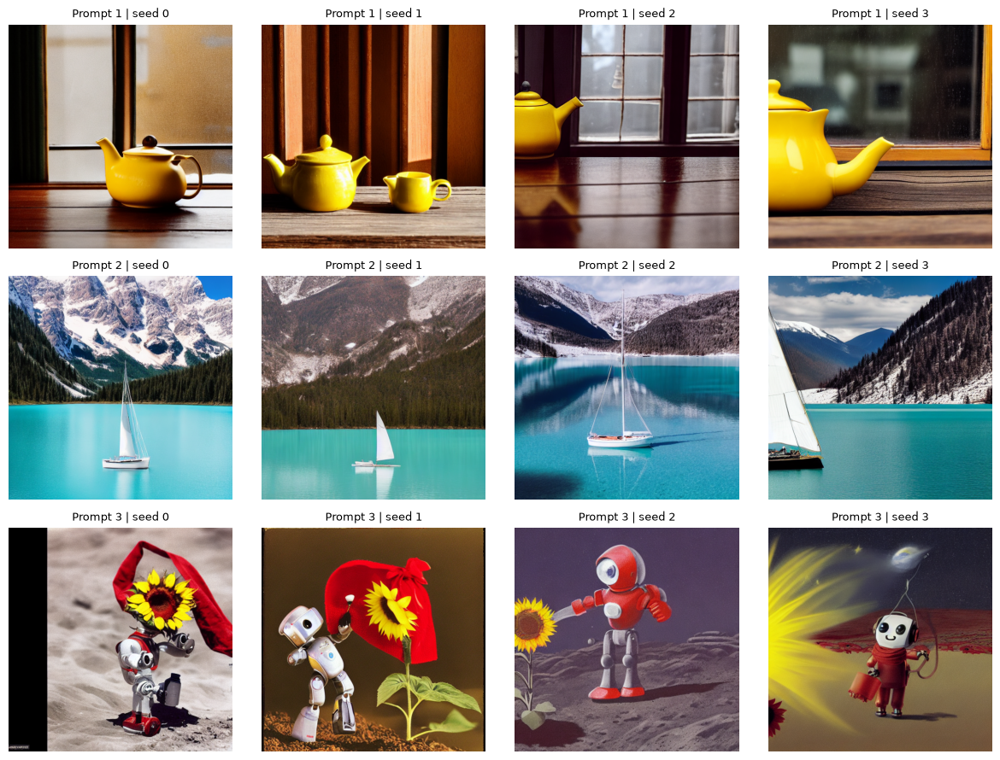

In [31]:
prompts = [
    'a photograph of a yellow ceramic teapot on a wooden table beside a rainy window',
    'a photograph of a white sailboat on a turquoise lake surrounded by snowy mountains',
    'a photograph of a small robot wearing a red scarf watering a sunflower on the moon, Earth in the sky',
]
seeds = [0,1,2,3]
for i,prompt in enumerate(prompts):
    print(f'Prompt {i+1}: {prompt}')
sd_images, sd_times = [], []
for p,prompt in enumerate(prompts):
    for seed in seeds:
        image,elapsed = timed_generate(pipe_sd,prompt,seed,25,7.5)
        sd_images.append(image); sd_times.append(elapsed)
        image.save(ARTIFACT_ROOT / f'sd_prompt{p+1}_seed{seed}.png')
        print(f'SD v1.5 prompt {p+1}, seed {seed}: {elapsed:.2f}s',flush=True)
titles = [f'Prompt {p+1} | seed {s}' for p in range(3) for s in seeds]
show_grid(sd_images,titles,ncols=4,filename='sd_seed_grid.png')
metrics['diffusion'] = {'prompts':prompts,'seeds':seeds,'sd_times':sd_times}
save_metrics()


Step experiment prompt: a photograph of a small robot wearing a red scarf watering a sunflower on the moon, Earth in the sky | seed: 0
5 DDIM steps: 0.87s
10 DDIM steps: 1.35s
25 DDIM steps: 3.13s
50 DDIM steps: 6.07s


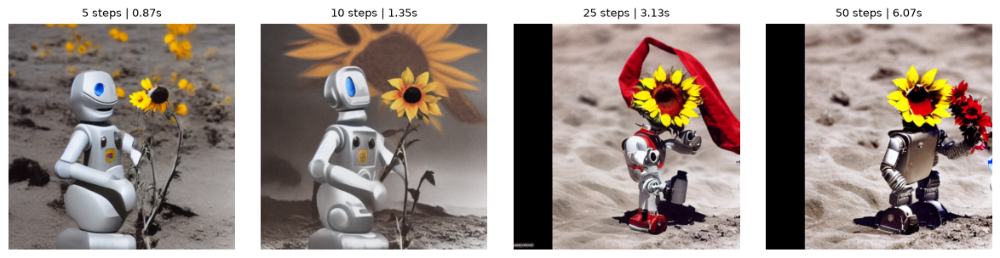

In [32]:
step_counts = [5,10,25,50]
step_images, step_times = [], []
step_prompt = prompts[2]
step_seed = 0
print('Step experiment prompt:', step_prompt, '| seed:',step_seed)
for steps in step_counts:
    image,elapsed = timed_generate(pipe_sd,step_prompt,step_seed,steps,7.5)
    step_images.append(image); step_times.append(elapsed)
    image.save(ARTIFACT_ROOT / f'sd_steps{steps}.png')
    print(f'{steps} DDIM steps: {elapsed:.2f}s',flush=True)
show_grid(step_images,[f'{s} steps | {t:.2f}s' for s,t in zip(step_counts,step_times)],
          ncols=4,filename='sd_step_grid.png')
metrics['diffusion'].update(step_counts=step_counts,step_times=step_times,
                          step_prompt=step_prompt,step_seed=step_seed)
save_metrics()


Loading pipeline components...: 100%|██████████| 5/5 [00:00<00:00,  9.47it/s]
You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


SD-Turbo prompt 1, seed 0: 0.25s
SD-Turbo prompt 1, seed 1: 0.25s
SD-Turbo prompt 1, seed 2: 0.25s
SD-Turbo prompt 1, seed 3: 0.24s
SD-Turbo prompt 2, seed 0: 0.25s
SD-Turbo prompt 2, seed 1: 0.26s
SD-Turbo prompt 2, seed 2: 0.25s
SD-Turbo prompt 2, seed 3: 0.25s
SD-Turbo prompt 3, seed 0: 0.25s
SD-Turbo prompt 3, seed 1: 0.25s
SD-Turbo prompt 3, seed 2: 0.25s
SD-Turbo prompt 3, seed 3: 0.25s


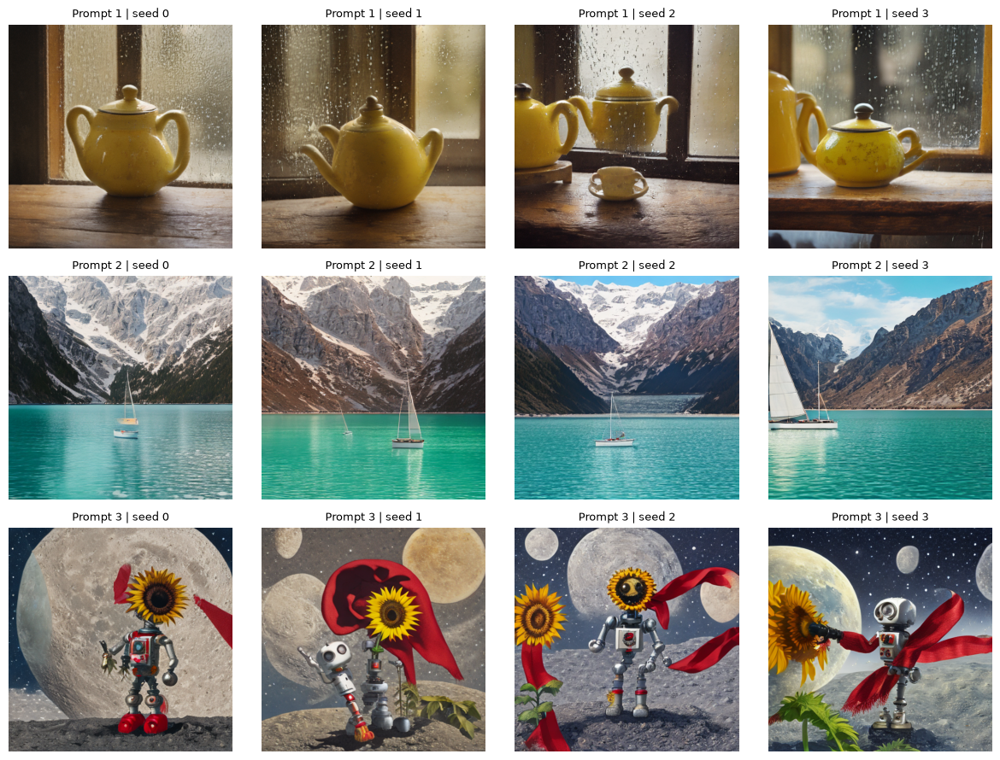

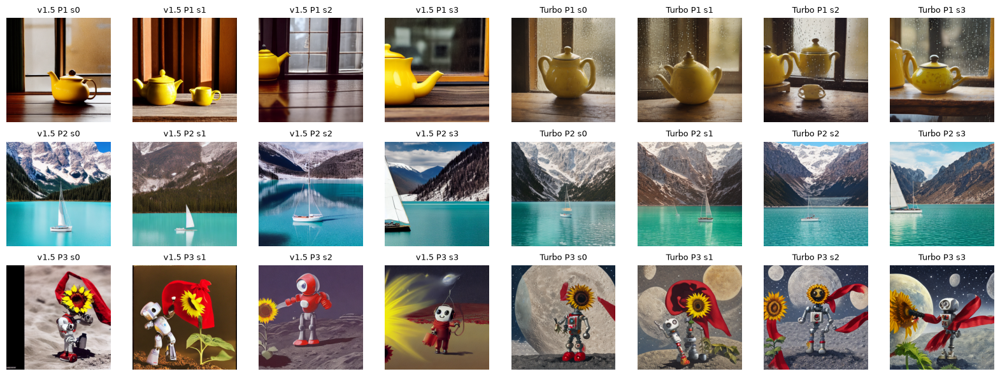

In [33]:
del pipe_sd
gc.collect()
torch.cuda.empty_cache()
import requests
for download_attempt in range(3):
    try:
        pipe_turbo = AutoPipelineForText2Image.from_pretrained(
            'stabilityai/sd-turbo', torch_dtype=torch.float16, variant='fp16',
            safety_checker=None).to('cuda')
        break
    except (requests.exceptions.ChunkedEncodingError, requests.exceptions.ConnectionError,
            requests.exceptions.Timeout) as error:
        if download_attempt == 2:
            raise
        print(f'Model download interrupted; resuming attempt {download_attempt+2}/3: {type(error).__name__}')
        time.sleep(2)
pipe_turbo.enable_vae_slicing()
pipe_turbo.set_progress_bar_config(disable=True)
generate(pipe_turbo,prompts[0],0,num_steps=1,guidance_scale=0.0)  # untimed warm-up
turbo_images, turbo_times = [], []
for p,prompt in enumerate(prompts):
    for seed in seeds:
        image,elapsed = timed_generate(pipe_turbo,prompt,seed,1,0.0)
        turbo_images.append(image); turbo_times.append(elapsed)
        image.save(ARTIFACT_ROOT / f'turbo_prompt{p+1}_seed{seed}.png')
        print(f'SD-Turbo prompt {p+1}, seed {seed}: {elapsed:.2f}s',flush=True)
show_grid(turbo_images,titles,ncols=4,filename='turbo_seed_grid.png')
# Three paired rows, each with four v1.5 seeds followed by four Turbo seeds.
comparison_images,comparison_titles = [],[]
for p in range(3):
    comparison_images.extend(sd_images[4*p:4*p+4]+turbo_images[4*p:4*p+4])
    comparison_titles.extend([f'v1.5 P{p+1} s{s}' for s in seeds] +
                             [f'Turbo P{p+1} s{s}' for s in seeds])
show_grid(comparison_images,comparison_titles,ncols=8,figsize_per_img=2,
          filename='model_comparison.png')
metrics['diffusion'].update(turbo_times=turbo_times,
    sd_mean_time=float(np.mean(sd_times)),turbo_mean_time=float(np.mean(turbo_times)))
save_metrics()
del pipe_turbo
gc.collect()
torch.cuda.empty_cache()


### Discussion 5 (noise)
For SD v1.5, how did changing the seed change the images? Was the diversity similar across your three prompts? Did any seed produce an image that does not match the prompt?

Changing the seed changed object scale, framing, and design: the teapot is fully visible for seeds 0–1 but cropped at the left for seeds 2–3, and the sailboat moves from a small centered object to a large boat at the frame edge. Diversity was greatest for the unusual prompt, whose robots vary from metallic toys to a red, cartoon-like character; the lake scenes keep a much more consistent photographic style. Some seeds clearly miss parts of the prompt: prompt 3 / seed 0 puts the sunflower near the robot’s head and the scarf above it rather than around its neck, with no visible Earth, while seed 3 departs from the requested photographic style. The presence of a robot and a flower is easier for this model than correctly composing all the requested attributes and relations.

### Discussion 6 (steps)
How did quality and generation time change from 5 to 50 DDIM steps? Around which number of steps did the improvement stop being noticeable?

For prompt 3 and seed 0, measured times were **5: 0.87 s, 10: 1.35 s, 25: 3.13 s, 50: 6.07 s** (DDIM steps). Even five steps produced a recognizable robot and sunflower, so additional steps were not simply fixing an unrecognizable image. The composition changed substantially: red scarf-like fabric appeared at 25 steps, while at 50 steps the robot’s head became more flower-like and metal/soil details sharpened. I saw diminishing, inconsistent visual gains beyond about 25 steps; doubling to 50 steps did not clearly improve prompt fidelity or recover the requested Earth and watering action.

### Discussion 7 (models)
Compare SD v1.5 and SD-Turbo on prompt fidelity, diversity across seeds, and speed. Which model handled your "unusual" prompt better? Give one hypothesis for the differences, considering that SD-Turbo is distilled to generate in a single step.

Mean generation time was **3.19 s** for SD v1.5 at 25 DDIM steps and guidance 7.5, versus **0.25 s** for one-step SD-Turbo with guidance 0 (12.8× faster), excluding model loading and untimed warm-up. Both models retained the yellow teapot and turquoise lake, but Turbo showed rainy-window droplets more consistently while sometimes producing malformed or duplicated teapots; SD v1.5 showed snowy surroundings more consistently. SD v1.5 had greater diversity in robot design and visual style, whereas Turbo stayed with metallic robots and repeated lunar/planet backgrounds. I preferred Turbo on the unusual prompt because its space setting and red fabric were more consistent, especially the neck scarf in seed 3, but neither model reliably depicted Earth or a clear watering action, and Turbo often merged the sunflower with the robot’s head. One hypothesis is that single-step distillation favors strong, familiar visual patterns without enough refinement for correct attribute binding; differences in pre-training, sampler, and guidance also matter, so these images do not isolate distillation as the cause.

---
**Before submitting:** make sure all outputs (accuracies, box visualizations, and generated image grids) are saved in the notebook and all Discussion cells are filled in.